<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/makemore_MLP_excercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
try:
  from google.colab import drive
  drive.mount('/content/drive')
  data_path = '/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt'
except ImportError:  # running locally
  data_path = 'Data/names.txt'
with open(data_path,'r') as f:
  text = f.read().splitlines()

Mounted at /content/drive


In [2]:
words = text
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [3]:
import torch
import torch.nn.functional as F
from matplotlib import pyplot as plt
%matplotlib inline

In [4]:
chars = sorted(list(set(''.join(words))))

In [12]:
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [6]:
block_size = 4

In [15]:
def build_dataset(words):
  X, Y = [], []
  for w in words:
      context = [0] * block_size
      for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]
  X=torch.tensor(X)
  Y=torch.tensor(Y)
  return X,Y

In [16]:
import random
random.seed(42)
random.shuffle(words)
n1 = int(len(words)*0.8)
n2 = int(len(words)*0.9)

Xtr,Ytr = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtes, Ytes = build_dataset(words[n2:])


In [17]:
Xtr.shape

torch.Size([182441, 4])

In [76]:
g = torch.Generator().manual_seed(45678)
C = torch.randn((27,10), generator=g)
W1= torch.randn((40,200),generator=g)
b1 = torch.randn(200,generator=g)
W2 = torch.randn((200,27),generator=g)
b2 = torch.randn(27,generator=g)
parameters = [C, W1, b1, W2, b2]

In [77]:
sum(p.nelement() for p in parameters)

13897

In [78]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre

In [79]:
for p in parameters:
  p.requires_grad=True

In [80]:
lri = []
lossi = []
stepi = []


In [81]:
for i in range(1000):
  # batch
  ix = torch.randint(0,Xval.shape[0], (50,))
  # foward pass
  emb = C[Xval[ix]]
  h = torch.tanh(emb.view(-1,40) @ W1 + b1)
  logits  = h @ W2 + b2
  loss = F.cross_entropy(logits, Yval[ix])
  # backward
  for p in parameters:
    p.grad = None
  loss.backward()
  # update

  lr = lrs[i]
  for p in parameters:
    p.data += -lr*p.grad

  # track
  lri.append(lre[i])
  lossi.append(loss.item())

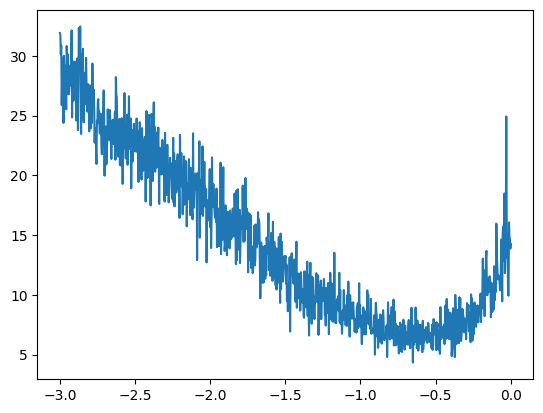

In [82]:
plt.plot(lri,lossi)

In [ ]:
# Therefore, pick -0.75

In [84]:
g = torch.Generator().manual_seed(6874)
C = torch.randn((27,10),generator=g)
W1 = torch.randn((40,200),generator=g)
b1 = torch.randn(200,generator=g)
W2 = torch.randn((200,27),generator=g)
b2 = torch.randn(27,generator=g)


In [85]:
parameters = [C,W1,b1,W2,b2]

In [86]:
for p in parameters:
  p.requires_grad=True

In [83]:
lossi = []
stepi = []


In [88]:
for i in range(40000):
  # batch
  ix = torch.randint(0,Xtr.shape[0],(50,))
  # forward pass
  emb = C[Xtr[ix]]
  h = torch.tanh(emb.view(-1,40) @ W1 + b1)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Ytr[ix])

  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # udpate
  lr = 10**(-0.75) if i < 10000 else 10**(-3)
  for p in parameters:
    p.data += -lr*p.grad
  # track
  lossi.append(loss.item())
  stepi.append(i)

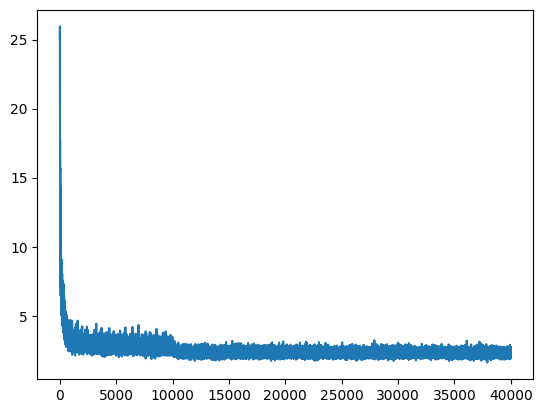

In [89]:
plt.plot(stepi,lossi)

In [91]:
emb = C[Xval]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yval)
loss

tensor(2.3252, grad_fn=<NllLossBackward0>)

In [92]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1,40) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.3065, grad_fn=<NllLossBackward0>)

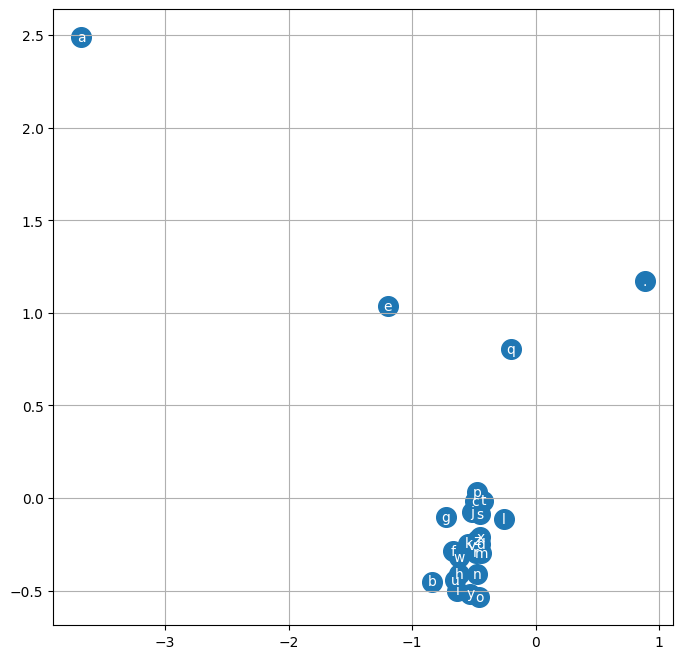

In [93]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

In [96]:
# predict
g = torch.Generator().manual_seed(42)
for _ in range(20):
  out = []
  context = [0] * block_size
  while True:
     emb = C[torch.tensor([context])]
     h = torch.tanh(emb.view(1,-1) @ W1 + b1)
     logits = h @ W2 + b2
     prob= F.softmax(logits,dim=1)
     ix = torch.multinomial(prob,num_samples=1,replacement=True,generator=g).item()
     context = context[1:]+[ix]
     out.append(ix)
     if ix==0:
      break
  print(''.join(itos[i] for i in out))

anuge.
nvigg.
mabi.
nedxe.
shan.
silayler.
kemah.
laman.
emiacelle.
jamzi.
kepon.
jordie.
kalla.
momolynn.
ahvisia.
anea.
kaitian.
tuhelina.
jace.
jenar.
